# Filtered Model Training (rate_code == 1 only)
## Testing if Removing Non-Standard Rate Codes Improves Model Performance

This notebook:
1. Loads original data and keeps only `rate_code == 1` (standard metered fare)
2. Applies the same preprocessing as `data_cleaning.ipynb`
3. Trains three models: Decision Tree, Small Neural Network, and XGBoost
4. Compares performance against the full dataset models

**Hypothesis**: Removing non-standard rate codes (airport flat fares, negotiated fares, etc.) will eliminate unpredictable trips and significantly improve R² scores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
import xgboost as xgb

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load and Filter Data (rate_code == 1 only)

In [2]:
print("="*80)
print("LOADING AND FILTERING DATA")
print("="*80)

# Load original data
df = pd.read_csv('bq-results-20251021-151536-1761059869369.csv', dtype_backend='pyarrow')
df.drop(columns=['data_file_year','data_file_month'], inplace=True)

print(f"Original dataset shape: {df.shape}")

# Check rate_code distribution BEFORE filtering
if 'rate_code' in df.columns:
    print("\n📊 Rate Code Distribution (BEFORE filtering):")
    rate_counts = df['rate_code'].value_counts().sort_index()
    print(rate_counts)
    print("\nPercentage:")
    print((rate_counts / len(df) * 100).round(2))
    
    # Filter to only rate_code == 1
    df_filtered = df[df['rate_code'] == 1].copy()
    
    removed_count = len(df) - len(df_filtered)
    removed_pct = (removed_count / len(df)) * 100
    
    print(f"\n✅ Filtered to rate_code == 1 only")
    print(f"   Removed: {removed_count:,} trips ({removed_pct:.2f}%)")
    print(f"   Remaining: {len(df_filtered):,} trips ({100-removed_pct:.2f}%)")
else:
    print("⚠️  WARNING: rate_code column not found!")
    df_filtered = df.copy()

LOADING AND FILTERING DATA
Original dataset shape: (1068744, 22)

📊 Rate Code Distribution (BEFORE filtering):
rate_code
1.0     626642
2.0       1800
3.0        314
4.0        654
5.0      26879
6.0          6
99.0        15
Name: count, dtype: int64[pyarrow]

Percentage:
rate_code
1.0     58.63
2.0      0.17
3.0      0.03
4.0      0.06
5.0      2.52
6.0       0.0
99.0      0.0
Name: count, dtype: double[pyarrow]

✅ Filtered to rate_code == 1 only
   Removed: 442,102 trips (41.37%)
   Remaining: 626,642 trips (58.63%)


## 2. Apply Data Cleaning (Same as data_cleaning.ipynb)

In [3]:
print("\n" + "="*80)
print("APPLYING DATA CLEANING")
print("="*80)

# Load taxi zone lookup for borough information
taxi_zone_lookup_df = pd.read_csv('taxi_zone_lookup.csv', dtype_backend='pyarrow')

# Merge for dropoff location
df_filtered = df_filtered.merge(taxi_zone_lookup_df[['LocationID', 'Borough']], 
                                 left_on='dropoff_location_id', right_on='LocationID', how='left')
df_filtered.rename(columns={'Borough': 'dropoff_borough'}, inplace=True)
df_filtered.drop(columns=['LocationID'], inplace=True)

# Merge for pickup location
df_filtered = df_filtered.merge(taxi_zone_lookup_df[['LocationID', 'Borough']], 
                                left_on='pickup_location_id', right_on='LocationID', how='left')
df_filtered.rename(columns={'Borough': 'pickup_borough'}, inplace=True)
df_filtered.drop(columns=['LocationID'], inplace=True)

# Drop location IDs
df_filtered.drop(columns=['dropoff_location_id', 'pickup_location_id'], inplace=True)

# Drop columns with all null values
df_filtered = df_filtered.dropna(axis=1, how='all')

# Process datetime
df_filtered['pickup_datetime'] = pd.to_datetime(df_filtered['pickup_datetime'])
df_filtered['dropoff_datetime'] = pd.to_datetime(df_filtered['dropoff_datetime'])
df_filtered['trip_duration'] = (df_filtered['dropoff_datetime'] - df_filtered['pickup_datetime']).dt.total_seconds() / 60
df_filtered.drop(columns=['dropoff_datetime'], inplace=True)

print(f"\nShape after datetime processing: {df_filtered.shape}")


APPLYING DATA CLEANING

Shape after datetime processing: (626642, 18)


In [4]:
# Apply validation rules (same as data_cleaning.ipynb)
print("\nApplying validation rules...")
initial_size = len(df_filtered)

df_filtered = df_filtered[df_filtered['trip_duration'] > 0]
df_filtered = df_filtered[df_filtered['trip_distance'] > 0]
df_filtered = df_filtered[df_filtered['total_amount'] > 0]
df_filtered = df_filtered[df_filtered['fare_amount'] > 0]
df_filtered = df_filtered[(df_filtered['payment_type'] >= 1) & (df_filtered['payment_type'] <= 6)]

removed = initial_size - len(df_filtered)
print(f"Removed {removed:,} invalid records ({removed/initial_size*100:.2f}%)")
print(f"Final dataset shape: {df_filtered.shape}")


Applying validation rules...
Removed 28,203 invalid records (4.50%)
Final dataset shape: (598439, 18)


In [5]:
# Drop columns (same as data_cleaning.ipynb)
cols_to_drop = ['vendor_id', 'pickup_datetime', 'rate_code', 'passenger_count', 
                'tip_amount', 'trip_type', 'imp_surcharge', 'store_and_fwd_flag']
df_filtered.drop(columns=[c for c in cols_to_drop if c in df_filtered.columns], inplace=True)

print(f"\nFinal columns: {df_filtered.columns.tolist()}")
print(f"Final shape: {df_filtered.shape}")
print("\nDataset info:")
df_filtered.info()


Final columns: ['trip_distance', 'fare_amount', 'extra', 'mta_tax', 'tolls_amount', 'total_amount', 'payment_type', 'dropoff_borough', 'pickup_borough', 'trip_duration']
Final shape: (598439, 10)

Dataset info:
<class 'pandas.core.frame.DataFrame'>
Index: 598439 entries, 14 to 626637
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype          
---  ------           --------------   -----          
 0   trip_distance    598439 non-null  double[pyarrow]
 1   fare_amount      598439 non-null  double[pyarrow]
 2   extra            598439 non-null  double[pyarrow]
 3   mta_tax          598439 non-null  double[pyarrow]
 4   tolls_amount     598439 non-null  double[pyarrow]
 5   total_amount     598439 non-null  double[pyarrow]
 6   payment_type     598439 non-null  double[pyarrow]
 7   dropoff_borough  596073 non-null  string[pyarrow]
 8   pickup_borough   597272 non-null  string[pyarrow]
 9   trip_duration    598439 non-null  float64        
dtypes: double[pyarro

In [6]:
# Check for missing values and impute if necessary
print("\n" + "="*80)
print("HANDLING MISSING VALUES")
print("="*80)

missing_before = df_filtered.isnull().sum().sum()
print(f"Missing values: {missing_before}")

if missing_before > 0:
    # Identify numeric and categorical columns
    numeric_cols = df_filtered.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = df_filtered.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
    
    # Remove target from numeric list
    if 'trip_duration' in numeric_cols:
        numeric_cols.remove('trip_duration')
    
    # Impute numeric columns with mean
    for col in numeric_cols:
        if df_filtered[col].isnull().sum() > 0:
            mean_val = df_filtered[col].mean()
            df_filtered[col].fillna(mean_val, inplace=True)
            print(f"  Imputed {col} with mean: {mean_val:.4f}")
    
    # Impute categorical columns with mode
    for col in categorical_cols:
        if df_filtered[col].isnull().sum() > 0:
            mode_val = df_filtered[col].mode()[0] if len(df_filtered[col].mode()) > 0 else 'Unknown'
            df_filtered[col].fillna(mode_val, inplace=True)
            print(f"  Imputed {col} with mode: {mode_val}")
    
    missing_after = df_filtered.isnull().sum().sum()
    print(f"\n✅ Missing values after imputation: {missing_after}")
else:
    print("✅ No missing values detected")


HANDLING MISSING VALUES
Missing values: 3533
  Imputed dropoff_borough with mode: Manhattan
  Imputed pickup_borough with mode: Manhattan

✅ Missing values after imputation: 0


In [7]:
# Summary statistics
print("\n" + "="*80)
print("FILTERED DATASET SUMMARY")
print("="*80)
print("\nTarget variable (trip_duration) statistics:")
print(df_filtered['trip_duration'].describe())

print("\nFirst few rows:")
display(df_filtered.head())


FILTERED DATASET SUMMARY

Target variable (trip_duration) statistics:
count    598439.000000
mean         23.702912
std          96.363836
min           0.016667
25%           7.516667
50%          12.166667
75%          19.883333
max        1439.850000
Name: trip_duration, dtype: float64

First few rows:


,trip_distance,fare_amount,extra,mta_tax,tolls_amount,total_amount,payment_type,dropoff_borough,pickup_borough,trip_duration
14,9.9,54.5,0.0,0.5,0.0,55.3,2.0,Brooklyn,Brooklyn,88.35
15,16.46,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,58.45
16,14.94,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,69.05
17,16.56,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,62.70
18,11.13,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,74.60


## 3. Prepare Data for Training

In [8]:
print("="*80)
print("PREPARING DATA FOR TRAINING")
print("="*80)

# Separate features and target
y = df_filtered['trip_duration'].values
X = df_filtered.drop('trip_duration', axis=1)

# Identify categorical columns
categorical_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
print(f"Categorical columns: {categorical_cols}")

# Split data first (80/20 train/test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTrain set size: {len(X_train):,}")
print(f"Test set size: {len(X_test):,}")
print(f"Train/Test split: {len(X_train)/(len(X_train)+len(X_test))*100:.1f}% / {len(X_test)/(len(X_train)+len(X_test))*100:.1f}%")

PREPARING DATA FOR TRAINING
Categorical columns: ['dropoff_borough', 'pickup_borough']

Train set size: 478,751
Test set size: 119,688
Train/Test split: 80.0% / 20.0%


In [22]:
# Helper function to evaluate models
def evaluate_model(y_true, y_pred, model_name):
    """Calculate and print regression metrics with visualization"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print(f"\n{'='*60}")
    print(f"{model_name} - Test Set Performance")
    print(f"{'='*60}")
    print(f"RMSE:     {rmse:.4f}")
    print(f"MAE:      {mae:.4f}")
    print(f"R² Score: {r2:.4f}")
    print(f"{'='*60}")
    
    # Create Real vs Predicted scatter plot
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Scatter plot
    ax.scatter(y_true, y_pred, alpha=0.5, s=50, edgecolors='k', linewidths=0.5)
    
    # Perfect prediction line (y=x)
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
    
    # Labels and title
    ax.set_xlabel('Actual Trip Duration (minutes)', fontsize=12)
    ax.set_ylabel('Predicted Trip Duration (minutes)', fontsize=12)
    ax.set_title(f'{model_name}\nActual vs Predicted Trip Duration\n(rate_code == 1 only)', 
                 fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 1400)  # This LIMITS the x-axis to 1400 minutes!
    ax.set_ylim(0, 1400)  # This LIMITS the y-axis to 1400 minutes!
    
    # Add metrics as text box
    textstr = f'RMSE: {rmse:.4f}\nMAE: {mae:.4f}\nR²: {r2:.4f}'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.show()
    
    return {'model': model_name, 'rmse': rmse, 'mae': mae, 'r2': r2}

# Store results for comparison
results = []

## 4. Model 1: Decision Tree Regressor

TRAINING DECISION TREE REGRESSOR
Decision Tree data shape: (478751, 19)

⏱️  Training time: 3.50 seconds

Decision Tree (rate_code=1) - Test Set Performance
RMSE:     97.8811
MAE:      14.6132
R² Score: -0.0219


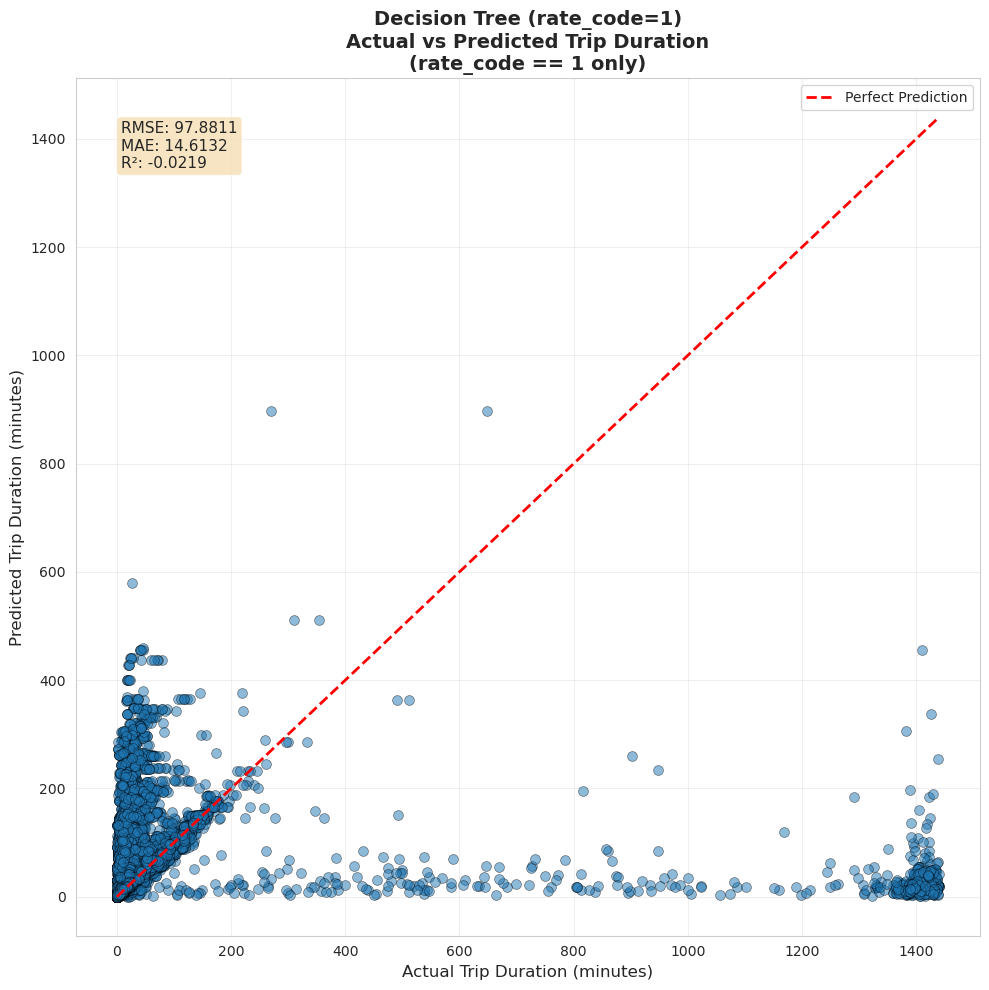

In [10]:
print("="*80)
print("TRAINING DECISION TREE REGRESSOR")
print("="*80)
start_time = time.time()

# Prepare data for Decision Tree: No scaling, convert categories to dummies
X_train_dt = X_train.copy()
X_test_dt = X_test.copy()

# Convert categorical columns to category dtype then create dummies
for col in categorical_cols:
    X_train_dt[col] = X_train_dt[col].astype('category')
    X_test_dt[col] = X_test_dt[col].astype('category')

X_train_dt = pd.get_dummies(X_train_dt, columns=categorical_cols, drop_first=True)
X_test_dt = pd.get_dummies(X_test_dt, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_dt, X_test_dt = X_train_dt.align(X_test_dt, join='left', axis=1, fill_value=0)

print(f"Decision Tree data shape: {X_train_dt.shape}")

# Decision Tree with reasonable hyperparameters
dt_model = DecisionTreeRegressor(
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt_model.fit(X_train_dt, y_train)
y_pred_dt = dt_model.predict(X_test_dt)

training_time = time.time() - start_time
print(f"\n⏱️  Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_dt, "Decision Tree (rate_code=1)"))

## 5. Model 2: Small Neural Network (PyTorch)

In [18]:
# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [19]:
# Define Small Neural Network (3 layers, no attention)
class SmallNN(nn.Module):
    def __init__(self, input_dim):
        super(SmallNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(64),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )
    
    def forward(self, x):
        return self.network(x)

In [20]:
print("="*80)
print("TRAINING SMALL NEURAL NETWORK")
print("="*80)
start_time = time.time()

# Prepare data for Neural Network: Mixed scaling approach
X_train_nn = X_train.copy()
X_test_nn = X_test.copy()

# Identify numeric columns (before creating dummies)
numeric_cols_all = [col for col in X_train_nn.columns if col not in categorical_cols]

# Separate columns for different scaling approaches
std_scaler_cols = ['mta_tax', 'extra']
power_transform_cols = [col for col in numeric_cols_all if col not in std_scaler_cols]

print(f"StandardScaler will be applied to: {std_scaler_cols}")
print(f"PowerTransformer will be applied to: {power_transform_cols}")

# Apply StandardScaler to mta_tax and extra
scaler_std = StandardScaler()
X_train_nn[std_scaler_cols] = scaler_std.fit_transform(X_train_nn[std_scaler_cols])
X_test_nn[std_scaler_cols] = scaler_std.transform(X_test_nn[std_scaler_cols])

# Apply PowerTransformer to other numeric columns
scaler_power = PowerTransformer()
X_train_nn[power_transform_cols] = scaler_power.fit_transform(X_train_nn[power_transform_cols])
X_test_nn[power_transform_cols] = scaler_power.transform(X_test_nn[power_transform_cols])

# NOW convert categorical columns to dummies (after scaling numeric features)
for col in categorical_cols:
    X_train_nn[col] = X_train_nn[col].astype('category')
    X_test_nn[col] = X_test_nn[col].astype('category')

X_train_nn = pd.get_dummies(X_train_nn, columns=categorical_cols, drop_first=True)
X_test_nn = pd.get_dummies(X_test_nn, columns=categorical_cols, drop_first=True)

# Ensure both train and test have the same columns
X_train_nn, X_test_nn = X_train_nn.align(X_test_nn, join='left', axis=1, fill_value=0)

# Ensure all columns are numeric
X_train_nn = X_train_nn.astype('float64').values
X_test_nn = X_test_nn.astype('float64').values

print(f"Neural Network data shape: {X_train_nn.shape}")

# Convert to tensors (keep on CPU for DataLoader)
X_train_tensor = torch.FloatTensor(X_train_nn)
y_train_tensor = torch.FloatTensor(y_train).unsqueeze(1)
X_test_tensor = torch.FloatTensor(X_test_nn).to(device)
y_test_tensor = torch.FloatTensor(y_test).unsqueeze(1).to(device)

input_dim = X_train_nn.shape[1]
print(f"Input dimension: {input_dim}")

TRAINING SMALL NEURAL NETWORK
StandardScaler will be applied to: ['mta_tax', 'extra']
PowerTransformer will be applied to: ['trip_distance', 'fare_amount', 'tolls_amount', 'total_amount', 'payment_type']
Neural Network data shape: (478751, 19)
Input dimension: 19



Training configuration:
  Epochs: 500
  Batch size: 128
  Learning rate: 0.001
  Optimizer: AdamW
  Loss: HuberLoss
  Early stopping patience: 15

Training started...
Early stopping at epoch 41

⏱️  Training time: 730.51 seconds

Small Neural Network (rate_code=1) - Test Set Performance
RMSE:     188.8389
MAE:      9.7609
R² Score: -2.8035


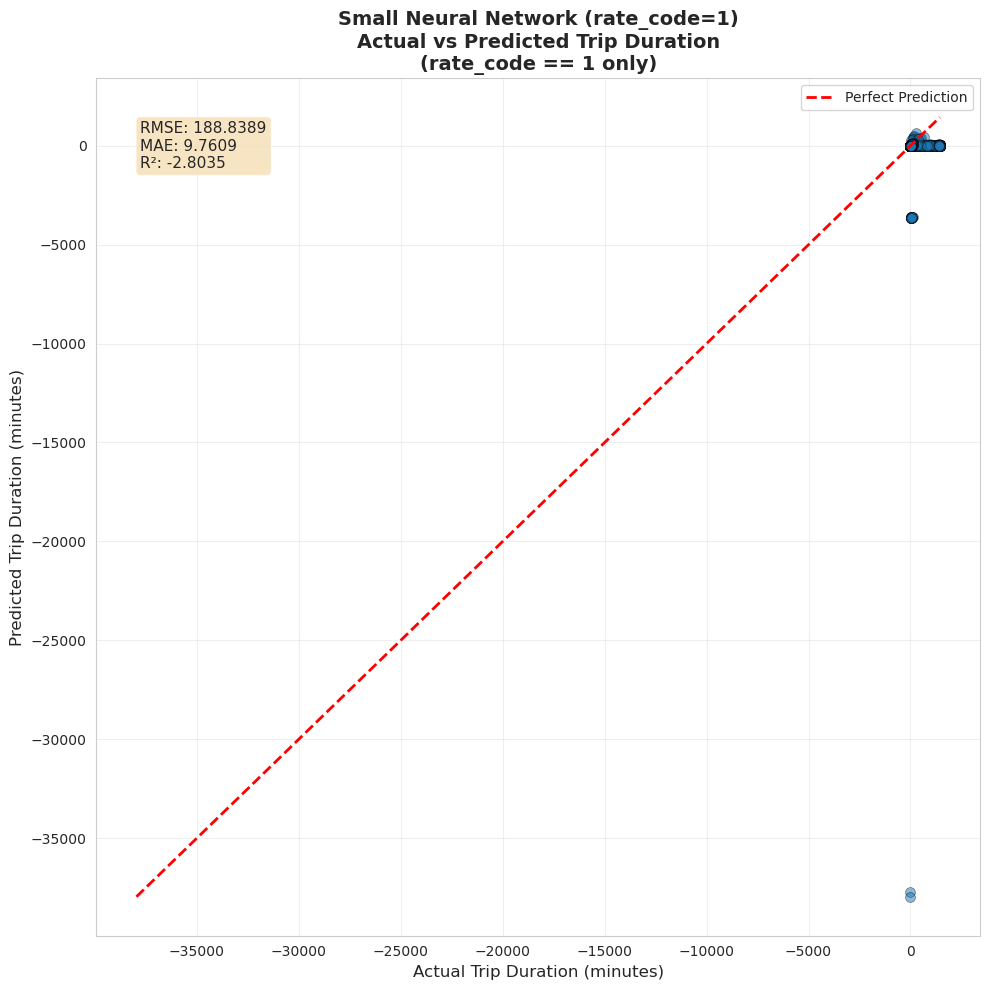

In [21]:
# Initialize model
nn_model = SmallNN(input_dim).to(device)

# Training configuration
criterion = nn.HuberLoss(delta=1.0)
optimizer = optim.AdamW(nn_model.parameters(), lr=0.001, weight_decay=1e-4, 
                        fused=True if device.type == 'cuda' else False)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6
)

# Training parameters
epochs = 500
patience = 15
best_loss = float('inf')
epochs_no_improve = 0
batch_size = 128

# Split train into train/validation
val_size = int(0.15 * len(X_train_tensor))
indices = torch.randperm(len(X_train_tensor))

X_tr = X_train_tensor[indices[val_size:]]
y_tr = y_train_tensor[indices[val_size:]]
X_val = X_train_tensor[indices[:val_size]].to(device)
y_val = y_train_tensor[indices[:val_size]].to(device)

# DataLoader
train_dataset = TensorDataset(X_tr, y_tr)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, 
                          pin_memory=True if device.type == 'cuda' else False)

print(f"\nTraining configuration:")
print(f"  Epochs: {epochs}")
print(f"  Batch size: {batch_size}")
print(f"  Learning rate: 0.001")
print(f"  Optimizer: AdamW")
print(f"  Loss: HuberLoss")
print(f"  Early stopping patience: {patience}")

# Training loop
print("\nTraining started...")
for epoch in range(epochs):
    nn_model.train()
    train_loss = 0.0
    
    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)
        
        optimizer.zero_grad(set_to_none=True)
        outputs = nn_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(nn_model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    
    # Validation
    nn_model.eval()
    with torch.no_grad():
        val_outputs = nn_model(X_val)
        val_loss = criterion(val_outputs, y_val).item()
    
    scheduler.step(val_loss)
    
    if val_loss < best_loss:
        best_loss = val_loss
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break
    
    if (epoch + 1) % 50 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, LR: {current_lr:.6f}")

# Predict on test set
nn_model.eval()
with torch.no_grad():
    y_pred_nn = nn_model(X_test_tensor).squeeze().cpu().numpy()

training_time = time.time() - start_time
print(f"\n⏱️  Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_nn, "Small Neural Network (rate_code=1)"))


aaSmall Neural Network (rate_code=1) - Test Set Performance
RMSE:     188.8389
MAE:      9.7609
R² Score: -2.8035


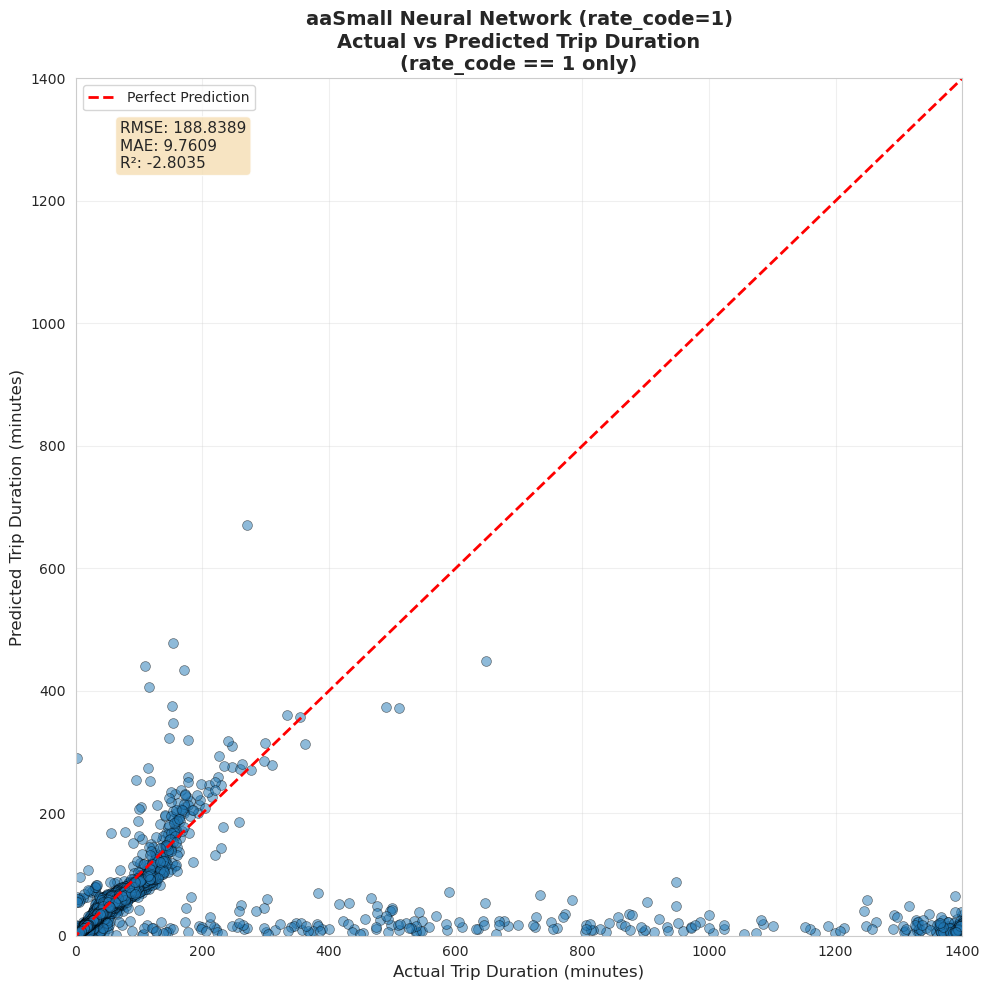

In [23]:
results.append(evaluate_model(y_test, y_pred_nn, "aaSmall Neural Network (rate_code=1)"))

## 6. Model 3: XGBoost Regressor

In [ ]:
print("="*80)
print("TRAINING XGBOOST REGRESSOR")
print("="*80)
start_time = time.time()

# Prepare data for XGBoost: No scaling, convert to numpy backend with str categories
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# Convert from pyarrow backend to numpy backend
numeric_cols = [col for col in X_train_xgb.columns if col not in categorical_cols]

# Convert numeric columns to float64 (numpy dtype)
for col in numeric_cols:
    X_train_xgb[col] = X_train_xgb[col].astype('float64')
    X_test_xgb[col] = X_test_xgb[col].astype('float64')

# Convert categorical columns from pyarrow string to python str wrapped in category
for col in categorical_cols:
    X_train_xgb[col] = X_train_xgb[col].astype(str).astype('category')
    X_test_xgb[col] = X_test_xgb[col].astype(str).astype('category')

print(f"XGBoost data shape: {X_train_xgb.shape}")
print(f"Categorical features: {categorical_cols}")

# XGBoost model
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    tree_method='hist',
    device='cuda' if device.type == 'cuda' else 'cpu',
    random_state=42,
    enable_categorical=True,
)

print(f"Training on: {'GPU' if device.type == 'cuda' else 'CPU'}")

xgb_model.fit(
    X_train_xgb, y_train,
    eval_set=[(X_test_xgb, y_test)],
    verbose=False
)

y_pred_xgb = xgb_model.predict(X_test_xgb)

training_time = time.time() - start_time
print(f"\n⏱️  Training time: {training_time:.2f} seconds")

results.append(evaluate_model(y_test, y_pred_xgb, "XGBoost (rate_code=1)"))

## 7. Model Comparison and Analysis

In [ ]:
# Create comparison DataFrame
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('r2', ascending=False)

print("\n" + "="*80)
print("MODEL COMPARISON - Filtered Dataset (rate_code == 1 only)")
print("="*80)
print(results_df.to_string(index=False))
print("="*80)

# Save results
results_df.to_csv('filtered_model_comparison.csv', index=False)
print("\n✅ Results saved to 'filtered_model_comparison.csv'")

In [ ]:
# Visualize model comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# R² comparison
axes[0].barh(results_df['model'], results_df['r2'], color='seagreen', alpha=0.7)
axes[0].set_xlabel('R² Score (higher is better)')
axes[0].set_title('R² Score Comparison')
axes[0].grid(True, alpha=0.3, axis='x')
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.5)

# RMSE comparison
axes[1].barh(results_df['model'], results_df['rmse'], color='steelblue', alpha=0.7)
axes[1].set_xlabel('RMSE (lower is better)')
axes[1].set_title('Root Mean Squared Error')
axes[1].grid(True, alpha=0.3, axis='x')

# MAE comparison
axes[2].barh(results_df['model'], results_df['mae'], color='coral', alpha=0.7)
axes[2].set_xlabel('MAE (lower is better)')
axes[2].set_title('Mean Absolute Error')
axes[2].grid(True, alpha=0.3, axis='x')

plt.suptitle('Model Performance on Filtered Dataset (rate_code == 1 only)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('filtered_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Visualization saved to 'filtered_model_comparison.png'")

## 8. Comparison with Original Models (Full Dataset)

In [ ]:
import os

print("="*80)
print("COMPARISON: FILTERED vs FULL DATASET")
print("="*80)

# Try to load results from the original model (full dataset)
if os.path.exists('model_comparison_results.csv'):
    original_results = pd.read_csv('model_comparison_results.csv')
    
    print("\n📊 Original Models (Full Dataset):")
    original_subset = original_results[original_results['model'].isin(['Decision Tree', 'XGBoost', 'Neural Network (PyTorch)'])]
    if len(original_subset) > 0:
        display(original_subset[['model', 'r2', 'rmse', 'mae']])
    
    print("\n📊 Filtered Models (rate_code == 1 only):")
    display(results_df[['model', 'r2', 'rmse', 'mae']])
    
    # Calculate improvement
    print("\n" + "="*80)
    print("IMPROVEMENT ANALYSIS")
    print("="*80)
    
    for _, filtered_row in results_df.iterrows():
        model_name_clean = filtered_row['model'].replace(' (rate_code=1)', '')
        
        # Find matching original model
        original_row = original_results[original_results['model'].str.contains(model_name_clean, case=False, na=False)]
        
        if len(original_row) > 0:
            original_row = original_row.iloc[0]
            r2_improvement = filtered_row['r2'] - original_row['r2']
            rmse_improvement = ((original_row['rmse'] - filtered_row['rmse']) / original_row['rmse']) * 100
            
            print(f"\n{model_name_clean}:")
            print(f"  R² Score:")
            print(f"    Full dataset:     {original_row['r2']:.4f}")
            print(f"    Filtered dataset: {filtered_row['r2']:.4f}")
            print(f"    Improvement:      {r2_improvement:+.4f}")
            print(f"  RMSE:")
            print(f"    Full dataset:     {original_row['rmse']:.4f}")
            print(f"    Filtered dataset: {filtered_row['rmse']:.4f}")
            print(f"    Improvement:      {rmse_improvement:+.2f}%")
            
            if r2_improvement > 0.1:
                print(f"  ✅ SIGNIFICANT IMPROVEMENT by filtering to rate_code=1!")
            elif r2_improvement > 0:
                print(f"  ✓ Slight improvement by filtering")
            else:
                print(f"  ⚠️  No improvement (or worse) after filtering")
else:
    print("\n⚠️  Original model results not found (model_comparison_results.csv)")
    print("   Run initial_match.ipynb first to compare with full dataset results")

## 9. Final Recommendations

In [ ]:
print("\n" + "="*80)
print("FINAL RECOMMENDATIONS")
print("="*80)

best_model = results_df.iloc[0]
print(f"\n🏆 Best Model: {best_model['model']}")
print(f"   R² Score: {best_model['r2']:.4f}")
print(f"   RMSE: {best_model['rmse']:.4f}")
print(f"   MAE: {best_model['mae']:.4f}")

# Check if filtering helped
if os.path.exists('model_comparison_results.csv'):
    original_results = pd.read_csv('model_comparison_results.csv')
    original_best_r2 = original_results['r2'].max()
    filtered_best_r2 = results_df['r2'].max()
    
    print(f"\n📈 Performance Summary:")
    print(f"   Best R² (Full Dataset):     {original_best_r2:.4f}")
    print(f"   Best R² (Filtered Dataset): {filtered_best_r2:.4f}")
    print(f"   Improvement:                {filtered_best_r2 - original_best_r2:+.4f}")
    
    if filtered_best_r2 > original_best_r2 + 0.1:
        print("\n✅ CONCLUSION: Filtering to rate_code=1 SIGNIFICANTLY IMPROVES performance!")
        print("   Recommendation: Use filtered dataset for production model")
        print("   The problematic trips (airport flat fares, negotiated fares) were")
        print("   indeed causing the poor predictions!")
    elif filtered_best_r2 > original_best_r2:
        print("\n✓ CONCLUSION: Filtering to rate_code=1 provides modest improvement")
        print("   Recommendation: Consider using filtered dataset if interpretability")
        print("   and consistency are priorities")
    else:
        print("\n⚠️  CONCLUSION: Filtering did not improve performance")
        print("   The issue may not be rate_code related")
        print("   Consider other factors (outliers, feature engineering, etc.)")
else:
    print("\n💡 NEXT STEPS:")
    print("   1. Run initial_match.ipynb to get full dataset baseline")
    print("   2. Compare filtered vs full dataset results")
    print("   3. Decide whether to use filtered or full dataset")

print("\n" + "="*80)